# Lab 04 – Fine-Tuning an LLM Using LoRA/QLoRA

Module: PUSL 3205 – Large Language Models and Generative AI

## Objective

To fine-tune a pretrained instruction-tuned language model
using parameter-efficient fine-tuning techniques.

This laboratory uses Qwen2.5-0.5B-Instruct and a custom
computer shop question-answer dataset to develop a
domain-specific AI customer service assistant.

In [2]:
%pip uninstall -y gradio gradio-client diffusers

Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [4]:
%pip install -q \
    "huggingface-hub==0.36.2" \
    "transformers>=4.56.2,<5" \
    "datasets>=3,<5" \
    "peft>=0.17.1,<0.19" \
    "trl==0.26.2" \
    "accelerate>=1.4,<2" \
    bitsandbytes

In [5]:
import os
import json
import gc
import random
import sys
import time

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import transformers
import datasets
import peft
import trl
import accelerate

from pathlib import Path
from datasets import Dataset

from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    set_seed
)

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

from trl import SFTTrainer, SFTConfig

from IPython.display import display

SEED = 42
set_seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import importlib.metadata as metadata

packages = [
    "torch",
    "transformers",
    "datasets",
    "peft",
    "trl",
    "accelerate",
    "bitsandbytes"
]

print("Python version:", sys.version)

for package in packages:
    print(package, ":", metadata.version(package))

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch : 2.14.1+cu130
transformers : 4.57.6
datasets : 4.8.5
peft : 0.18.1
trl : 0.26.2
accelerate : 1.15.0
bitsandbytes : 0.50.2


In [7]:
project_dir = Path(
    "/content/Lab-04-LLM-Fine-Tuning"
)

data_dir = project_dir / "data"
models_dir = project_dir / "models"
results_dir = project_dir / "results"
screenshots_dir = project_dir / "screenshots"

for folder in [
    data_dir,
    models_dir,
    results_dir,
    screenshots_dir
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project folders created successfully!")

print("Project directory:", project_dir)

Project folders created successfully!
Project directory: /content/Lab-04-LLM-Fine-Tuning


In [8]:
print("GPU Available:", torch.cuda.is_available())

if not torch.cuda.is_available():

    raise RuntimeError(
        "GPU is not available. "
        "Enable a GPU in Colab runtime settings."
    )

gpu_name = torch.cuda.get_device_name(0)

gpu_memory = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

gpu_information = {

    "gpu_name": gpu_name,

    "gpu_memory_gib": round(gpu_memory, 2),

    "cuda_version": torch.version.cuda,

    "pytorch_version": str(torch.__version__)

}

print("GPU Name:", gpu_name)

print(f"GPU Memory: {gpu_memory:.2f} GiB")

print("CUDA Version:", torch.version.cuda)

with open(
    results_dir / "gpu_information.json",
    "w"
) as file:

    json.dump(
        gpu_information,
        file,
        indent=4
    )

GPU Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GiB
CUDA Version: 13.0


In [9]:
!nvidia-smi

Thu Nov 26 15:09:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## GPU Information

GPU Name: NVIDIA Tesla T4

GPU Memory: 16 GB

### Why is a GPU useful for LLM fine-tuning?

GPUs support parallel mathematical operations,
including matrix multiplication and tensor processing.

This accelerates forward propagation, backpropagation
and parameter optimization during language model
fine-tuning.

GPU acceleration reduces training time compared
with CPU-based training.

In [10]:
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

SYSTEM_PROMPT = (
    "You are the customer service assistant "
    "for TechZone Computer Shop. "
    "Provide accurate and concise answers "
    "about TechZone products and services. "
    "Do not invent unknown shop policies."
)

# False = standard LoRA
# True = 4-bit QLoRA

USE_QLORA = False

USE_BF16 = torch.cuda.is_bf16_supported()

COMPUTE_DTYPE = (
    torch.bfloat16
    if USE_BF16
    else torch.float16
)

print("Selected model:", MODEL_ID)

print(
    "Fine-tuning method:",
    "QLoRA" if USE_QLORA else "LoRA"
)

print("Mixed precision dtype:", COMPUTE_DTYPE)

Selected model: Qwen/Qwen2.5-0.5B-Instruct
Fine-tuning method: LoRA
Mixed precision dtype: torch.bfloat16


In [11]:
qa_pairs = [

    (
        "What is the name of your computer shop?",
        "Our computer shop is called TechZone."
    ),

    (
        "Where is TechZone located?",
        "TechZone is located in Colombo, Sri Lanka."
    ),

    (
        "What are your opening hours?",
        "TechZone is open from 9 AM to 7 PM, Monday to Saturday."
    ),

    (
        "Are you open on Sundays?",
        "No. TechZone is closed on Sundays."
    ),

    (
        "Do you sell laptops?",
        "Yes. TechZone sells laptops for students, professionals and gamers."
    ),

    (
        "What laptop brands do you sell?",
        "We sell ASUS, Dell, HP, Lenovo, Acer and MSI laptops."
    ),

    (
        "Do you sell gaming laptops?",
        "Yes. TechZone offers gaming laptops with dedicated NVIDIA graphics cards."
    ),

    (
        "How much is the student laptop package?",
        "The TechZone student laptop package starts at LKR 145,000."
    ),

    (
        "How much is your basic gaming PC?",
        "The TechZone basic gaming PC starts at LKR 220,000."
    ),

    (
        "Do you sell desktop computers?",
        "Yes. We sell office desktops, gaming PCs and custom-built computers."
    ),

    (
        "Can you build a custom gaming PC?",
        "Yes. TechZone provides custom PC building services based on customer budgets."
    ),

    (
        "Do you sell computer monitors?",
        "Yes. We sell office monitors, gaming monitors and high-resolution displays."
    ),

    (
        "Do you sell SSD storage?",
        "Yes. We sell SATA and NVMe SSDs in different capacities."
    ),

    (
        "Do you sell RAM?",
        "Yes. TechZone sells DDR4 and DDR5 RAM for compatible computers."
    ),

    (
        "Do you sell graphics cards?",
        "Yes. We sell NVIDIA and AMD graphics cards."
    ),

    (
        "Do you provide laptop repair services?",
        "Yes. TechZone provides laptop diagnosis and repair services."
    ),

    (
        "How much is a laptop diagnosis?",
        "The standard laptop diagnostic fee is LKR 1,500."
    ),

    (
        "How much does laptop cleaning cost?",
        "The TechZone standard laptop cleaning service costs LKR 3,500."
    ),

    (
        "Can you replace a laptop screen?",
        "Yes. TechZone replaces damaged laptop screens with compatible panels."
    ),

    (
        "Can you replace a laptop battery?",
        "Yes. We provide laptop battery replacement services for supported models."
    ),

    (
        "Can you upgrade my laptop RAM?",
        "Yes. We upgrade laptop RAM when the device supports memory upgrades."
    ),

    (
        "Can you upgrade my laptop to an SSD?",
        "Yes. TechZone provides SSD installation and upgrade services."
    ),

    (
        "Do you install Windows?",
        "Yes. We provide Windows installation using genuine licensed software."
    ),

    (
        "Do you provide a warranty for new laptops?",
        "New laptops sold by TechZone include a one-year standard warranty."
    ),

    (
        "What is the warranty for laptop repairs?",
        "TechZone provides a 90-day warranty for eligible repair services."
    ),

    (
        "What is your return policy?",
        "Eligible unused products can be returned within seven days with the original receipt."
    ),

    (
        "Do you provide home delivery?",
        "Yes. TechZone provides islandwide delivery within Sri Lanka."
    ),

    (
        "How much is the delivery charge?",
        "The standard TechZone delivery charge is LKR 750."
    ),

    (
        "How long does delivery take?",
        "Standard delivery takes two to four working days."
    ),

    (
        "What payment methods do you accept?",
        "TechZone accepts cash, debit cards, credit cards and bank transfers."
    ),

    (
        "Do university students receive discounts?",
        "Yes. Students receive a five percent discount on eligible accessories with a valid student ID."
    ),

    (
        "Do you sell keyboards and mice?",
        "Yes. We sell wired and wireless keyboards and mice."
    ),

    (
        "Do you sell laptop chargers?",
        "Yes. TechZone sells compatible replacement laptop chargers."
    ),

    (
        "Can I book a repair appointment?",
        "Yes. Customers can book repair appointments through the TechZone customer service team."
    ),

    (
        "How can I check my repair status?",
        "Contact TechZone customer service and provide your repair reference number."
    ),

    (
        "Do you provide data backup services?",
        "Yes. TechZone offers data backup services with customer authorization."
    )

]

train_df = pd.DataFrame(

    qa_pairs,

    columns=["question", "answer"]

)

print("Training dataset size:", len(train_df))

display(train_df)

Training dataset size: 36


,question,answer
0,What is the name of your computer shop?,Our computer shop is called TechZone.
1,Where is TechZone located?,"TechZone is located in Colombo, Sri Lanka."
2,What are your opening hours?,"TechZone is open from 9 AM to 7 PM, Monday to ..."
3,Are you open on Sundays?,No. TechZone is closed on Sundays.
4,Do you sell laptops?,"Yes. TechZone sells laptops for students, prof..."
5,What laptop brands do you sell?,"We sell ASUS, Dell, HP, Lenovo, Acer and MSI l..."
6,Do you sell gaming laptops?,Yes. TechZone offers gaming laptops with dedic...
7,How much is the student laptop package?,The TechZone student laptop package starts at ...
8,How much is your basic gaming PC?,The TechZone basic gaming PC starts at LKR 220...
9,Do you sell desktop computers?,"Yes. We sell office desktops, gaming PCs and c..."


In [12]:
validation_pairs = [

    (
        "When does your shop close on weekdays?",
        "TechZone closes at 7 PM."
    ),

    (
        "Can you deliver a computer outside Colombo?",
        "Yes. TechZone provides islandwide delivery within Sri Lanka."
    ),

    (
        "What is the fee for checking a faulty laptop?",
        "The standard laptop diagnostic fee is LKR 1,500."
    ),

    (
        "What warranty period applies to eligible repairs?",
        "Eligible TechZone repair services include a 90-day warranty."
    ),

    (
        "How many working days are needed for delivery?",
        "Standard delivery takes two to four working days."
    ),

    (
        "Can I get a discount with my university ID?",
        "Yes. A valid student ID provides a five percent discount on eligible accessories."
    )

]

validation_df = pd.DataFrame(

    validation_pairs,

    columns=["question", "answer"]

)

print("Training examples:", len(train_df))

print("Validation examples:", len(validation_df))

print(
    "Total examples:",
    len(train_df) + len(validation_df)
)

display(validation_df)

Training examples: 36
Validation examples: 6
Total examples: 42


,question,answer
0,When does your shop close on weekdays?,TechZone closes at 7 PM.
1,Can you deliver a computer outside Colombo?,Yes. TechZone provides islandwide delivery wit...
2,What is the fee for checking a faulty laptop?,"The standard laptop diagnostic fee is LKR 1,500."
3,What warranty period applies to eligible repairs?,Eligible TechZone repair services include a 90...
4,How many working days are needed for delivery?,Standard delivery takes two to four working days.
5,Can I get a discount with my university ID?,Yes. A valid student ID provides a five percen...


In [13]:
print("Dataset information:")

train_df.info()

print("\nMissing values:")

print(train_df.isnull().sum())

print("\nDuplicate questions:")

print(train_df["question"].duplicated().sum())

train_df["question_words"] = (
    train_df["question"].str.split().str.len()
)

train_df["answer_words"] = (
    train_df["answer"].str.split().str.len()
)

print("\nText length statistics:")

display(

    train_df[
        ["question_words", "answer_words"]
    ].describe()

)

assert len(train_df) >= 30

assert not train_df[
    ["question", "answer"]
].isnull().any().any()

assert not train_df["question"].duplicated().any()

assert set(train_df["question"]).isdisjoint(
    set(validation_df["question"])
)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   question  36 non-null     object
 1   answer    36 non-null     object
dtypes: object(2)
memory usage: 708.0+ bytes

Missing values:
question    0
answer      0
dtype: int64

Duplicate questions:
0

Text length statistics:


,question_words,answer_words
count,36.000000,36.000000
mean,5.750000,9.361111
std,1.105183,1.822914
min,4.000000,6.000000
25%,5.000000,8.000000
50%,6.000000,9.000000
75%,6.000000,10.000000
max,8.000000,15.000000


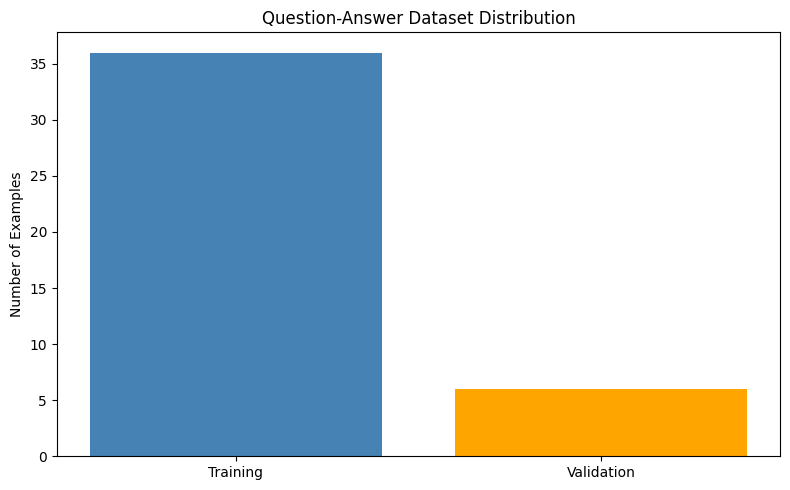

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(

    ["Training", "Validation"],

    [len(train_df), len(validation_df)],

    color=["steelblue", "orange"]

)

plt.title("Question-Answer Dataset Distribution")

plt.ylabel("Number of Examples")

plt.tight_layout()

plt.savefig(

    results_dir / "dataset_distribution.png",

    dpi=300

)

plt.show()

In [15]:
train_df[["question", "answer"]].to_csv(

    data_dir / "training_dataset.csv",

    index=False

)

validation_df.to_csv(

    data_dir / "validation_dataset.csv",

    index=False

)

print("Datasets saved successfully!")

Datasets saved successfully!


In [16]:
tokenizer = AutoTokenizer.from_pretrained(

    MODEL_ID

)

if tokenizer.pad_token is None:

    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

print("Tokenizer loaded successfully!")

print("Vocabulary size:", len(tokenizer))

print("EOS token:", tokenizer.eos_token)

print("Padding token:", tokenizer.pad_token)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 151665
EOS token: <|im_end|>
Padding token: <|endoftext|>


In [17]:
def format_example(row):

    return {

        "prompt": [

            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },

            {
                "role": "user",
                "content": row["question"]
            }

        ],

        "completion": [

            {
                "role": "assistant",
                "content": row["answer"]
            }

        ]

    }


train_dataset = Dataset.from_list([

    format_example(row)

    for _, row in train_df.iterrows()

])

eval_dataset = Dataset.from_list([

    format_example(row)

    for _, row in validation_df.iterrows()

])

print(train_dataset)

print(eval_dataset)

print("\nFormatted example:\n")

print(

    json.dumps(

        train_dataset[0],

        indent=4

    )

)

Dataset({
    features: ['prompt', 'completion'],
    num_rows: 36
})
Dataset({
    features: ['prompt', 'completion'],
    num_rows: 6
})

Formatted example:

{
    "prompt": [
        {
            "content": "You are the customer service assistant for TechZone Computer Shop. Provide accurate and concise answers about TechZone products and services. Do not invent unknown shop policies.",
            "role": "system"
        },
        {
            "content": "What is the name of your computer shop?",
            "role": "user"
        }
    ],
    "completion": [
        {
            "content": "Our computer shop is called TechZone.",
            "role": "assistant"
        }
    ]
}


In [18]:
example = train_dataset[0]

formatted_text = tokenizer.apply_chat_template(

    example["prompt"] + example["completion"],

    tokenize=False,

    add_generation_prompt=False

)

print(formatted_text)

<|im_start|>system
You are the customer service assistant for TechZone Computer Shop. Provide accurate and concise answers about TechZone products and services. Do not invent unknown shop policies.<|im_end|>
<|im_start|>user
What is the name of your computer shop?<|im_end|>
<|im_start|>assistant
Our computer shop is called TechZone.<|im_end|>



In [19]:
bnb_config = None

if USE_QLORA:

    bnb_config = BitsAndBytesConfig(

        load_in_4bit=True,

        bnb_4bit_quant_type="nf4",

        bnb_4bit_compute_dtype=COMPUTE_DTYPE,

        bnb_4bit_use_double_quant=True

    )

    print("4-bit QLoRA configuration created.")

else:

    print("Standard LoRA selected.")

    print("4-bit quantization is disabled.")

Standard LoRA selected.
4-bit quantization is disabled.


In [20]:
if USE_QLORA:

    model = AutoModelForCausalLM.from_pretrained(

        MODEL_ID,

        quantization_config=bnb_config,

        torch_dtype=COMPUTE_DTYPE,

        device_map={"": 0}

    )

else:

    model = AutoModelForCausalLM.from_pretrained(

        MODEL_ID,

        torch_dtype=torch.float32

    )

    model = model.to("cuda")


model.config.pad_token_id = tokenizer.pad_token_id

print("Base model loaded successfully!")

print("Model device:", next(model.parameters()).device)

print(

    "Model memory footprint (GiB):",

    round(

        model.get_memory_footprint() / (1024 ** 3),

        3

    )

)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Base model loaded successfully!
Model device: cuda:0
Model memory footprint (GiB): 1.84


In [21]:
@torch.inference_mode()

def generate_response(

    current_model,

    question,

    max_new_tokens=100

):

    current_model.eval()

    messages = [

        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },

        {
            "role": "user",
            "content": question
        }

    ]

    text = tokenizer.apply_chat_template(

        messages,

        tokenize=False,

        add_generation_prompt=True

    )

    inputs = tokenizer(

        text,

        return_tensors="pt",

        add_special_tokens=False

    ).to(

        current_model.get_input_embeddings().weight.device

    )

    outputs = current_model.generate(

        **inputs,

        max_new_tokens=max_new_tokens,

        do_sample=False,

        use_cache=True,

        pad_token_id=tokenizer.pad_token_id

    )

    generated_tokens = outputs[

        0,

        inputs["input_ids"].shape[1]:

    ]

    response = tokenizer.decode(

        generated_tokens,

        skip_special_tokens=True

    )

    return response.strip()

In [22]:
test_cases = [

    {

        "question": "What are your opening hours?",

        "expected": "9 AM to 7 PM, Monday to Saturday.",

        "type": "Seen"

    },

    {

        "question": "How much does laptop cleaning cost?",

        "expected": "LKR 3,500.",

        "type": "Seen"

    },

    {

        "question": "How much is the delivery charge?",

        "expected": "LKR 750.",

        "type": "Seen"

    },

    {

        "question": "What is the starting price of a computer for gaming?",

        "expected": "LKR 220,000.",

        "type": "Unseen"

    },

    {

        "question": "Is your store operating on Sunday?",

        "expected": "No. The store is closed on Sundays.",

        "type": "Unseen"

    },

    {

        "question": "What is the cost of the laptop package for students?",

        "expected": "Starting from LKR 145,000.",

        "type": "Unseen"

    },

    {

        "question": "For how long are brand-new notebooks covered by warranty?",

        "expected": "One-year standard warranty.",

        "type": "Unseen"

    },

    {

        "question": "What is the total price for laptop diagnosis and cleaning?",

        "expected": "LKR 5,000.",

        "type": "Unseen - Reasoning"

    }

]

test_df = pd.DataFrame(test_cases)

unseen_questions = test_df.loc[
    test_df["type"] != "Seen",
    "question"
]

assert set(unseen_questions).isdisjoint(
    set(train_df["question"])
)

assert set(test_df["question"]).isdisjoint(
    set(validation_df["question"])
)

test_df.to_csv(

    data_dir / "test_dataset.csv",

    index=False

)

display(test_df)

,question,expected,type
0,What are your opening hours?,"9 AM to 7 PM, Monday to Saturday.",Seen
1,How much does laptop cleaning cost?,"LKR 3,500.",Seen
2,How much is the delivery charge?,LKR 750.,Seen
3,What is the starting price of a computer for g...,"LKR 220,000.",Unseen
4,Is your store operating on Sunday?,No. The store is closed on Sundays.,Unseen
5,What is the cost of the laptop package for stu...,"Starting from LKR 145,000.",Unseen
6,For how long are brand-new notebooks covered b...,One-year standard warranty.,Unseen
7,What is the total price for laptop diagnosis a...,"LKR 5,000.",Unseen - Reasoning


In [23]:
original_responses = []

for case in test_cases:

    question = case["question"]

    answer = generate_response(

        model,

        question

    )

    original_responses.append(answer)

    print("=" * 70)

    print("Question:", question)

    print("\nExpected Answer:")

    print(case["expected"])

    print("\nOriginal Model Response:")

    print(answer)

    print()


original_results_df = test_df.copy()

original_results_df["original_response"] = (
    original_responses
)

original_results_df.to_csv(

    results_dir / "original_model_responses.csv",

    index=False

)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Question: What are your opening hours?

Expected Answer:
9 AM to 7 PM, Monday to Saturday.

Original Model Response:
I'm sorry, but I don't have real-time information on my opening hours as I am a virtual assistant. However, you can check the official website or contact their customer service directly to get the most up-to-date details regarding their business hours.

Question: How much does laptop cleaning cost?

Expected Answer:
LKR 3,500.

Original Model Response:
The cost of laptop cleaning can vary depending on several factors, including the brand of your laptop, the type of cleaning solution you choose, and how thorough or intensive the cleaning is. Generally, a basic laptop cleaner might cost around $5 to $10 per clean, while more advanced models with specialized cleaning solutions could cost upwards of $20 to $30.

For professional-grade cleaning, consider investing in a high-quality laptop cleaner that includes features like UV light sterilization, which can be quite

Question

In [24]:
lora_config = LoraConfig(

    r=16,

    lora_alpha=32,

    target_modules="all-linear",

    lora_dropout=0.05,

    bias="none",

    task_type="CAUSAL_LM"

)

print("LoRA configuration created!")

print(lora_config)

LoRA configuration created!
LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.18.1', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules='all-linear', exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, use_dora=False, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, arrow_config=None, ensure_weight_tying=False)


In [25]:
if USE_QLORA:

    model = prepare_model_for_kbit_training(

        model,

        use_gradient_checkpointing=False

    )

model = get_peft_model(

    model,

    lora_config

)

model.config.use_cache = False

model.print_trainable_parameters()

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


In [26]:
trainable_parameters, total_parameters = (
    model.get_nb_trainable_parameters()
)

frozen_parameters = (
    total_parameters - trainable_parameters
)

trainable_percentage = (

    trainable_parameters

    / total_parameters

    * 100

)

parameter_df = pd.DataFrame({

    "Parameter Type": [

        "Trainable Parameters",

        "Frozen Parameters",

        "Total Parameters"

    ],

    "Count": [

        trainable_parameters,

        frozen_parameters,

        total_parameters

    ]

})

display(parameter_df)

print(

    f"Trainable parameter percentage: "

    f"{trainable_percentage:.4f}%"

)

parameter_df.to_csv(

    results_dir / "parameter_analysis.csv",

    index=False

)

,Parameter Type,Count
0,Trainable Parameters,8798208
1,Frozen Parameters,494032768
2,Total Parameters,502830976


Trainable parameter percentage: 1.7497%


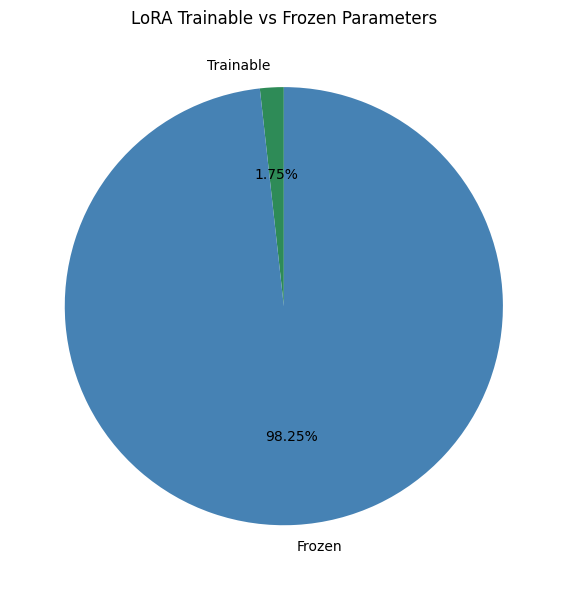

In [27]:
plt.figure(figsize=(8, 6))

plt.pie(

    [

        trainable_parameters,

        frozen_parameters

    ],

    labels=[

        "Trainable",

        "Frozen"

    ],

    autopct="%1.2f%%",

    colors=[

        "seagreen",

        "steelblue"

    ],

    startangle=90

)

plt.title("LoRA Trainable vs Frozen Parameters")

plt.tight_layout()

plt.savefig(

    results_dir / "parameter_distribution.png",

    dpi=300

)

plt.show()

In [28]:
training_args = SFTConfig(

    output_dir=str(
        models_dir / "training_checkpoints"
    ),

    num_train_epochs=8,

    per_device_train_batch_size=2,

    per_device_eval_batch_size=2,

    gradient_accumulation_steps=2,

    learning_rate=2e-4,

    warmup_ratio=0.1,

    weight_decay=0.01,

    lr_scheduler_type="cosine",

    logging_strategy="steps",

    logging_steps=1,

    eval_strategy="epoch",

    save_strategy="no",

    fp16=not USE_BF16,

    bf16=USE_BF16,

    gradient_checkpointing=False,

    max_grad_norm=1.0,

    optim="adamw_torch",

    max_length=256,

    packing=False,

    completion_only_loss=True,

    eos_token="<|im_end|>",

    report_to="none",

    seed=SEED

)

print("Training configuration created!")

Training configuration created!


In [29]:
trainer = SFTTrainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=eval_dataset,

    processing_class=tokenizer

)

print("SFTTrainer initialized successfully!")

Tokenizing train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/6 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/6 [00:00<?, ? examples/s]

SFTTrainer initialized successfully!


In [30]:
gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

print("Starting fine-tuning...\n")

training_result = trainer.train()

training_time = time.perf_counter() - start_time

print("\nFine-tuning completed!")

print(

    f"Training time: "

    f"{training_time:.2f} seconds"

)

print(

    f"Final average training loss: "

    f"{training_result.training_loss:.4f}"

)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Starting fine-tuning...



Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,1.272100,1.760583,2.696241,2379.000000,0.606676
2,0.749800,1.063498,2.367421,4758.000000,0.673786
3,0.874100,0.775747,1.635843,7137.000000,0.800187
4,0.351500,0.619716,1.398734,9516.000000,0.814192
5,0.229000,0.638546,1.328198,11895.000000,0.837885
6,0.077500,0.643455,1.325710,14274.000000,0.857493
7,0.032800,0.762644,1.251809,16653.000000,0.867297
8,0.020000,0.775679,1.241510,19032.000000,0.867297



Fine-tuning completed!
Training time: 115.46 seconds
Final average training loss: 0.5293


In [31]:
training_metrics = dict(

    training_result.metrics

)

training_metrics["gpu_name"] = gpu_name

training_metrics["method"] = (

    "QLoRA" if USE_QLORA else "LoRA"

)

training_metrics["training_time_seconds"] = (
    training_time
)

training_metrics["peak_gpu_memory_gib"] = (

    torch.cuda.max_memory_allocated()

    / (1024 ** 3)

)

training_metrics["trainable_parameters"] = (
    trainable_parameters
)

training_metrics["trainable_percentage"] = (
    trainable_percentage
)

with open(

    results_dir / "training_metrics.json",

    "w"

) as file:

    json.dump(

        training_metrics,

        file,

        indent=4

    )

display(

    pd.DataFrame([training_metrics])

)

,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss,epoch,gpu_name,method,training_time_seconds,peak_gpu_memory_gib,trainable_parameters,trainable_percentage
0,113.9419,2.528,0.632,4.285067e+13,0.529283,8.0,Tesla T4,LoRA,115.464215,3.588954,8798208,1.749735


In [32]:
history_df = pd.DataFrame(

    trainer.state.log_history

)

history_df.to_csv(

    results_dir / "training_history.csv",

    index=False

)

display(history_df)

,loss,grad_norm,learning_rate,entropy,num_tokens,mean_token_accuracy,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_num_tokens,eval_mean_token_accuracy,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.9322,17.645967,0.000000e+00,2.236027,256.0,0.428205,0.111111,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.6524,19.121168,2.500000e-05,2.238032,520.0,0.487455,0.222222,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.8764,14.941809,5.000000e-05,2.273000,780.0,0.501045,0.333333,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2.6054,19.302826,7.500000e-05,2.246986,1044.0,0.561494,0.444444,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.6499,8.658497,1.000000e-04,2.372010,1309.0,0.583333,0.555556,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,0.0212,1.582930,1.082349e-06,1.209023,18502.0,1.000000,7.777778,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77,0.0121,0.640879,4.815273e-07,1.209104,18768.0,1.000000,7.888889,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
78,0.0200,0.664858,1.204544e-07,1.239983,19032.0,1.000000,8.000000,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,72,0.775679,0.4087,14.681,7.34,1.24151,19032.0,0.867297,NaN,NaN,NaN,NaN,NaN


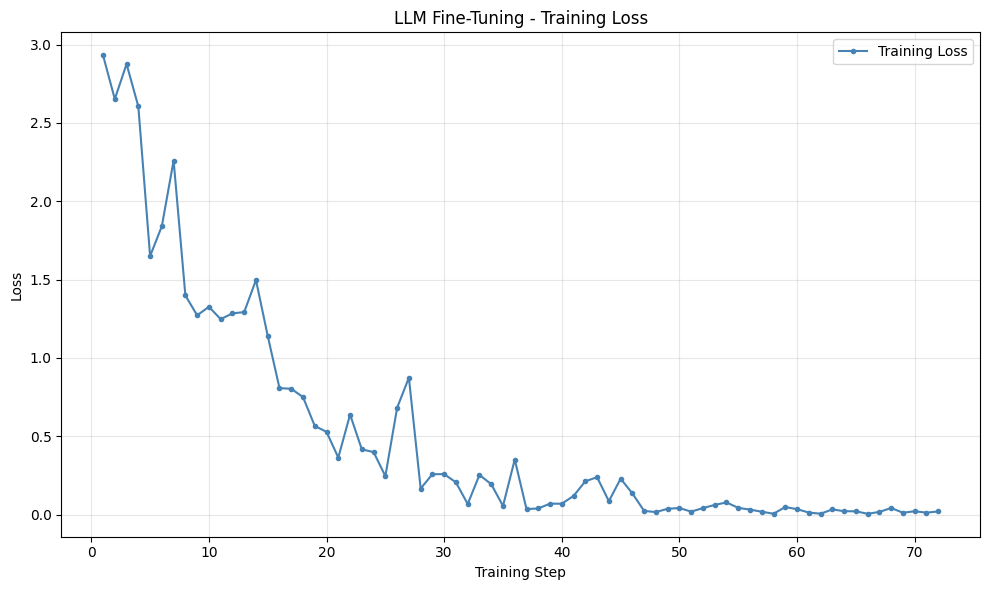

In [33]:
loss_df = history_df.dropna(

    subset=["loss"]

)

plt.figure(figsize=(10, 6))

plt.plot(

    loss_df["step"],

    loss_df["loss"],

    color="steelblue",

    marker="o",

    markersize=3,

    label="Training Loss"

)

plt.title("LLM Fine-Tuning - Training Loss")

plt.xlabel("Training Step")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    results_dir / "training_loss.png",

    dpi=300

)

plt.show()

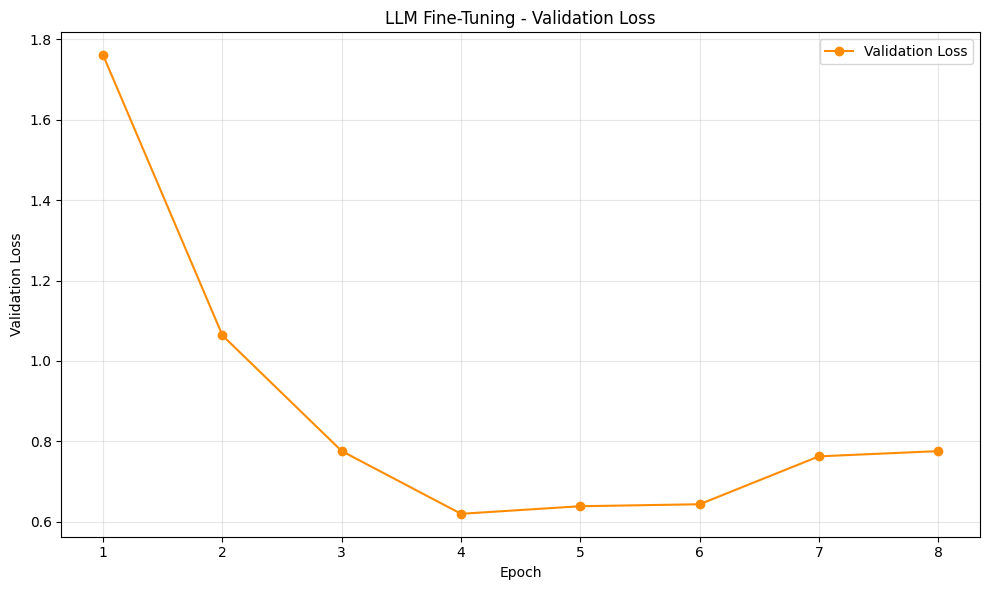

In [34]:
eval_history_df = history_df.dropna(

    subset=["eval_loss"]

)

plt.figure(figsize=(10, 6))

plt.plot(

    eval_history_df["epoch"],

    eval_history_df["eval_loss"],

    marker="o",

    color="darkorange",

    label="Validation Loss"

)

plt.title("LLM Fine-Tuning - Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Validation Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    results_dir / "validation_loss.png",

    dpi=300

)

plt.show()

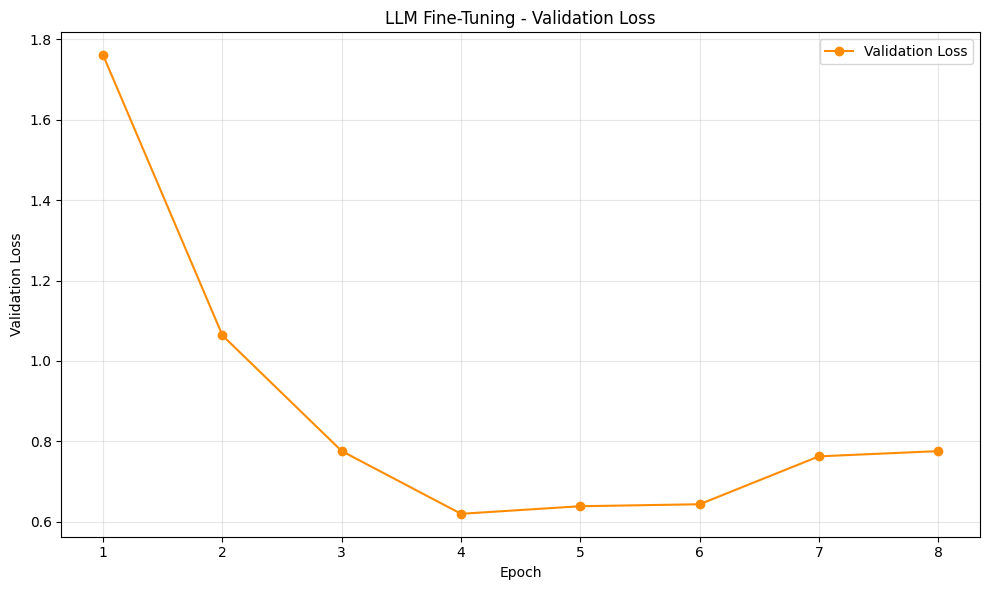

In [35]:
eval_history_df = history_df.dropna(

    subset=["eval_loss"]

)

plt.figure(figsize=(10, 6))

plt.plot(

    eval_history_df["epoch"],

    eval_history_df["eval_loss"],

    marker="o",

    color="darkorange",

    label="Validation Loss"

)

plt.title("LLM Fine-Tuning - Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Validation Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    results_dir / "validation_loss.png",

    dpi=300

)

plt.show()

In [36]:
import math

evaluation_metrics = trainer.evaluate()

validation_loss = evaluation_metrics["eval_loss"]

perplexity = math.exp(validation_loss)

evaluation_metrics["perplexity"] = perplexity

print("FINAL MODEL EVALUATION")

print("=" * 50)

print(

    f"Validation Loss: "

    f"{validation_loss:.4f}"

)

print(

    f"Validation Perplexity: "

    f"{perplexity:.4f}"

)

with open(

    results_dir / "evaluation_metrics.json",

    "w"

) as file:

    json.dump(

        evaluation_metrics,

        file,

        indent=4

    )

FINAL MODEL EVALUATION
Validation Loss: 0.7757
Validation Perplexity: 2.1721


In [47]:
fine_tuned_model = trainer.model

fine_tuned_model.eval()

fine_tuned_responses = []

for case in test_cases:

    question = case["question"]

    answer = generate_response(

        fine_tuned_model,

        question

    )

    fine_tuned_responses.append(answer)

    print("=" * 70)

    print("Question:", question)

    print("\nExpected Answer:")

    print(case["expected"])

    print("\nFine-Tuned Model Response:")

    print(answer)

    print()


fine_tuned_results_df = test_df.copy()

fine_tuned_results_df["fine_tuned_response"] = (

    fine_tuned_responses

)

fine_tuned_results_df.to_csv(

    results_dir / "fine_tuned_model_responses.csv",

    index=False

)

Question: What are your opening hours?

Expected Answer:
9 AM to 7 PM, Monday to Saturday.

Fine-Tuned Model Response:
TechZone is open from 9 AM to 7 PM, Monday to Saturday.

Question: How much does laptop cleaning cost?

Expected Answer:
LKR 3,500.

Fine-Tuned Model Response:
The TechZone standard laptop cleaning service costs LKR 3,500.

Question: How much is the delivery charge?

Expected Answer:
LKR 750.

Fine-Tuned Model Response:
The standard TechZone delivery charge is LKR 750.

Question: What is the starting price of a computer for gaming?

Expected Answer:
LKR 220,000.

Fine-Tuned Model Response:
The TechZone starting gaming PC starts at LKR 240,000.

Question: Is your store operating on Sunday?

Expected Answer:
No. The store is closed on Sundays.

Fine-Tuned Model Response:
No. TechZone is open from 9 AM to 7 PM, Monday to Saturday.

Question: What is the cost of the laptop package for students?

Expected Answer:
Starting from LKR 145,000.

Fine-Tuned Model Response:
The Te

In [48]:
comparison_df = test_df.copy()

comparison_df["original_response"] = (

    original_responses

)

comparison_df["fine_tuned_response"] = (

    fine_tuned_responses

)

pd.set_option(

    "display.max_colwidth",

    None

)

display(comparison_df)

comparison_df.to_csv(

    results_dir / "model_comparison.csv",

    index=False

)

,question,expected,type,original_response,fine_tuned_response
0,What are your opening hours?,"9 AM to 7 PM, Monday to Saturday.",Seen,"I'm sorry, but I don't have real-time information on my opening hours as I am a virtual assistant. However, you can check the official website or contact their customer service directly to get the most up-to-date details regarding their business hours.","TechZone is open from 9 AM to 7 PM, Monday to Saturday."
1,How much does laptop cleaning cost?,"LKR 3,500.",Seen,"The cost of laptop cleaning can vary depending on several factors, including the brand of your laptop, the type of cleaning solution you choose, and how thorough or intensive the cleaning is. Generally, a basic laptop cleaner might cost around $5 to $10 per clean, while more advanced models with specialized cleaning solutions could cost upwards of $20 to $30.\n\nFor professional-grade cleaning, consider investing in a high-quality laptop cleaner that includes features like UV light sterilization, which can be quite","The TechZone standard laptop cleaning service costs LKR 3,500."
2,How much is the delivery charge?,LKR 750.,Seen,"I'm sorry, but I don't have specific information on a particular delivery charge for TechZone Computer Shop. Delivery charges can vary depending on factors such as location, time of day, and whether you're ordering online or in-store. It's best to check directly with TechZone or their customer service for the most up-to-date pricing details. If you need this information urgently, you might consider contacting them through their website or phone number.",The standard TechZone delivery charge is LKR 750.
3,What is the starting price of a computer for gaming?,"LKR 220,000.",Unseen,"The starting price of a computer for gaming can vary widely depending on several factors, including the brand, model, and specifications. Generally, the most popular and high-end gaming computers start around $1,000 to $2,500 or more. However, there are also budget-friendly options available that range from under $300 to over $400.\n\nFor example:\n- **Intel Core i7**: Starting at around $800-$1,200","The TechZone starting gaming PC starts at LKR 240,000."
4,Is your store operating on Sunday?,No. The store is closed on Sundays.,Unseen,"Our store is currently open Monday through Friday, with a limited opening time on Saturdays from 10:00 AM to 2:00 PM. We do offer some weekend promotions and events, but we don't have any specific information about our Sunday hours at this time. If you're looking for details, it's best to check directly with our customer service team or visit our website for the most up-to-date information.","No. TechZone is open from 9 AM to 7 PM, Monday to Saturday."
5,What is the cost of the laptop package for students?,"Starting from LKR 145,000.",Unseen,"The cost of a laptop package for students at TechZone Computer Shop typically includes the following components:\n\n1. **Laptop**: A standard laptop with a 15-inch screen, usually priced around $700-$800.\n2. **Case**: A standard case that fits the laptop, costing approximately $30-$40.\n3. **Battery**: A battery pack that can last up to 10 hours, which costs around $20-$30.\n4.","The TechZone laptop package starts at LKR 145,000."
6,For how long are brand-new notebooks covered by warranty?,One-year standard warranty.,Unseen,"The warranty period for brand-new notebooks varies depending on the specific model and manufacturer, but generally, most brands offer a 1-year or 2-year warranty. It's important to check the product specifications provided with your notebook for exact terms. For example, some models might have a longer warranty period due to manufacturing processes or quality control measures. Always refer to the official product manual or contact the manufacturer directly for the most up-to-date information.",A TechZone brand-new notebook comes with a one-year standard warranty.
7,What is the total price for laptop diagnosis and cleaning?,"LKR 5,000.",Unseen

In [49]:
for _, row in comparison_df.iterrows():

    print("=" * 80)

    print("Question Type:", row["type"])

    print("\nQUESTION:")

    print(row["question"])

    print("\nEXPECTED ANSWER:")

    print(row["expected"])

    print("\nORIGINAL MODEL:")

    print(row["original_response"])

    print("\nFINE-TUNED MODEL:")

    print(row["fine_tuned_response"])

    print()

Question Type: Seen

QUESTION:
What are your opening hours?

EXPECTED ANSWER:
9 AM to 7 PM, Monday to Saturday.

ORIGINAL MODEL:
I'm sorry, but I don't have real-time information on my opening hours as I am a virtual assistant. However, you can check the official website or contact their customer service directly to get the most up-to-date details regarding their business hours.

FINE-TUNED MODEL:
TechZone is open from 9 AM to 7 PM, Monday to Saturday.

Question Type: Seen

QUESTION:
How much does laptop cleaning cost?

EXPECTED ANSWER:
LKR 3,500.

ORIGINAL MODEL:
The cost of laptop cleaning can vary depending on several factors, including the brand of your laptop, the type of cleaning solution you choose, and how thorough or intensive the cleaning is. Generally, a basic laptop cleaner might cost around $5 to $10 per clean, while more advanced models with specialized cleaning solutions could cost upwards of $20 to $30.

For professional-grade cleaning, consider investing in a high-qual

In [50]:
original_scores = []

fine_tuned_scores = []


def get_score(label):

    while True:

        score = input(

            f"{label} (1 = Correct, 0 = Incorrect): "

        ).strip()

        if score in ["0", "1"]:

            return int(score)

        print("Please enter 0 or 1.")


for _, row in comparison_df.iterrows():

    print("\n" + "=" * 70)

    print("Question:", row["question"])

    print("Expected:", row["expected"])

    print("\nOriginal:", row["original_response"])

    original_scores.append(

        get_score("Original model score")

    )

    print("\nFine-tuned:", row["fine_tuned_response"])

    fine_tuned_scores.append(

        get_score("Fine-tuned model score")

    )


comparison_df["original_correct"] = original_scores

comparison_df["fine_tuned_correct"] = fine_tuned_scores

comparison_df.to_csv(

    results_dir / "scored_model_comparison.csv",

    index=False

)

display(comparison_df)


Question: What are your opening hours?
Expected: 9 AM to 7 PM, Monday to Saturday.

Original: I'm sorry, but I don't have real-time information on my opening hours as I am a virtual assistant. However, you can check the official website or contact their customer service directly to get the most up-to-date details regarding their business hours.
Original model score (1 = Correct, 0 = Incorrect): 0

Fine-tuned: TechZone is open from 9 AM to 7 PM, Monday to Saturday.
Fine-tuned model score (1 = Correct, 0 = Incorrect): 1

Question: How much does laptop cleaning cost?
Expected: LKR 3,500.

Original: The cost of laptop cleaning can vary depending on several factors, including the brand of your laptop, the type of cleaning solution you choose, and how thorough or intensive the cleaning is. Generally, a basic laptop cleaner might cost around $5 to $10 per clean, while more advanced models with specialized cleaning solutions could cost upwards of $20 to $30.

For professional-grade cleaning, 

,question,expected,type,original_response,fine_tuned_response,original_correct,fine_tuned_correct
0,What are your opening hours?,"9 AM to 7 PM, Monday to Saturday.",Seen,"I'm sorry, but I don't have real-time information on my opening hours as I am a virtual assistant. However, you can check the official website or contact their customer service directly to get the most up-to-date details regarding their business hours.","TechZone is open from 9 AM to 7 PM, Monday to Saturday.",0,1
1,How much does laptop cleaning cost?,"LKR 3,500.",Seen,"The cost of laptop cleaning can vary depending on several factors, including the brand of your laptop, the type of cleaning solution you choose, and how thorough or intensive the cleaning is. Generally, a basic laptop cleaner might cost around $5 to $10 per clean, while more advanced models with specialized cleaning solutions could cost upwards of $20 to $30.\n\nFor professional-grade cleaning, consider investing in a high-quality laptop cleaner that includes features like UV light sterilization, which can be quite","The TechZone standard laptop cleaning service costs LKR 3,500.",0,1
2,How much is the delivery charge?,LKR 750.,Seen,"I'm sorry, but I don't have specific information on a particular delivery charge for TechZone Computer Shop. Delivery charges can vary depending on factors such as location, time of day, and whether you're ordering online or in-store. It's best to check directly with TechZone or their customer service for the most up-to-date pricing details. If you need this information urgently, you might consider contacting them through their website or phone number.",The standard TechZone delivery charge is LKR 750.,0,1
3,What is the starting price of a computer for gaming?,"LKR 220,000.",Unseen,"The starting price of a computer for gaming can vary widely depending on several factors, including the brand, model, and specifications. Generally, the most popular and high-end gaming computers start around $1,000 to $2,500 or more. However, there are also budget-friendly options available that range from under $300 to over $400.\n\nFor example:\n- **Intel Core i7**: Starting at around $800-$1,200","The TechZone starting gaming PC starts at LKR 240,000.",0,1
4,Is your store operating on Sunday?,No. The store is closed on Sundays.,Unseen,"Our store is currently open Monday through Friday, with a limited opening time on Saturdays from 10:00 AM to 2:00 PM. We do offer some weekend promotions and events, but we don't have any specific information about our Sunday hours at this time. If you're looking for details, it's best to check directly with our customer service team or visit our website for the most up-to-date information.","No. TechZone is open from 9 AM to 7 PM, Monday to Saturday.",0,1
5,What is the cost of the laptop package for students?,"Starting from LKR 145,000.",Unseen,"The cost of a laptop package for students at TechZone Computer Shop typically includes the following components:\n\n1. **Laptop**: A standard laptop with a 15-inch screen, usually priced around $700-$800.\n2. **Case**: A standard case that fits the laptop, costing approximately $30-$40.\n3. **Battery**: A battery pack that can last up to 10 hours, which costs around $20-$30.\n4.","The TechZone laptop package starts at LKR 145,000.",0,1
6,For how long are brand-new notebooks covered by warranty?,One-year standard warranty.,Unseen,"The warranty period for brand-new notebooks varies depending on the specific model and manufacturer, but generally, most brands offer a 1-year or 2-year warranty. It's important to check the product specifications provided with your notebook for exact terms. For example, some models might have a longer warranty period due to manufacturing processes or quality control measures. Always refer to the official product manual or contact the manufacturer directly for the most up-to-date information.",A TechZone brand-new notebook comes with a one-year standard warranty.,0,1
7,What is the to

In [51]:
original_accuracy = (

    comparison_df["original_correct"].mean()

    * 100

)

fine_tuned_accuracy = (

    comparison_df["fine_tuned_correct"].mean()

    * 100

)

improvement = (

    fine_tuned_accuracy - original_accuracy

)

accuracy_df = pd.DataFrame({

    "Model": [

        "Original Model",

        "Fine-Tuned Model"

    ],

    "Accuracy": [

        original_accuracy,

        fine_tuned_accuracy

    ]

})

display(accuracy_df)

print(

    f"Original Model Accuracy: "

    f"{original_accuracy:.2f}%"

)

print(

    f"Fine-Tuned Model Accuracy: "

    f"{fine_tuned_accuracy:.2f}%"

)

print(

    f"Accuracy Difference: "

    f"{improvement:.2f} percentage points"

)

accuracy_df.to_csv(

    results_dir / "accuracy_comparison.csv",

    index=False

)

,Model,Accuracy
0,Original Model,0.0
1,Fine-Tuned Model,87.5


Original Model Accuracy: 0.00%
Fine-Tuned Model Accuracy: 87.50%
Accuracy Difference: 87.50 percentage points


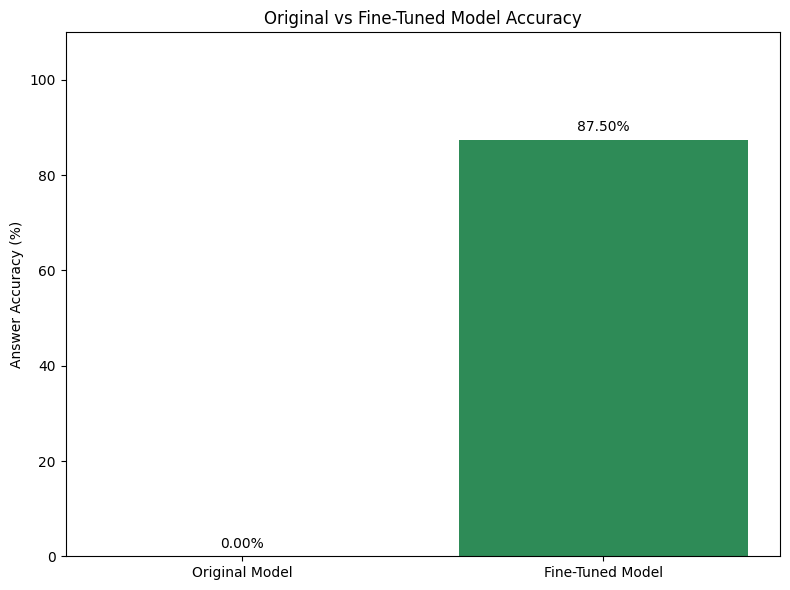

In [53]:
plt.figure(figsize=(8, 6))

bars = plt.bar(

    accuracy_df["Model"],

    accuracy_df["Accuracy"],

    color=[

        "steelblue",

        "seagreen"

    ]

)

plt.bar_label(

    bars,

    fmt="%.2f%%",

    padding=4

)

plt.title("Original vs Fine-Tuned Model Accuracy")

plt.ylabel("Answer Accuracy (%)")

plt.ylim(0, 110)

plt.tight_layout()

plt.savefig(

    results_dir / "accuracy_comparison.png",

    dpi=300

)

plt.show()

In [54]:
unseen_df = comparison_df[

    comparison_df["type"] != "Seen"

]

seen_df = comparison_df[

    comparison_df["type"] == "Seen"

]

category_results = []

for category, subset in [

    ("Seen Questions", seen_df),

    ("Unseen Questions", unseen_df)

]:

    category_results.append({

        "Category": category,

        "Number of Questions": len(subset),

        "Original Accuracy": (

            subset["original_correct"].mean() * 100

        ),

        "Fine-Tuned Accuracy": (

            subset["fine_tuned_correct"].mean() * 100

        )

    })


category_df = pd.DataFrame(category_results)

display(category_df)

category_df.to_csv(

    results_dir / "category_comparison.csv",

    index=False

)

,Category,Number of Questions,Original Accuracy,Fine-Tuned Accuracy
0,Seen Questions,3,0.0,100.0
1,Unseen Questions,5,0.0,80.0


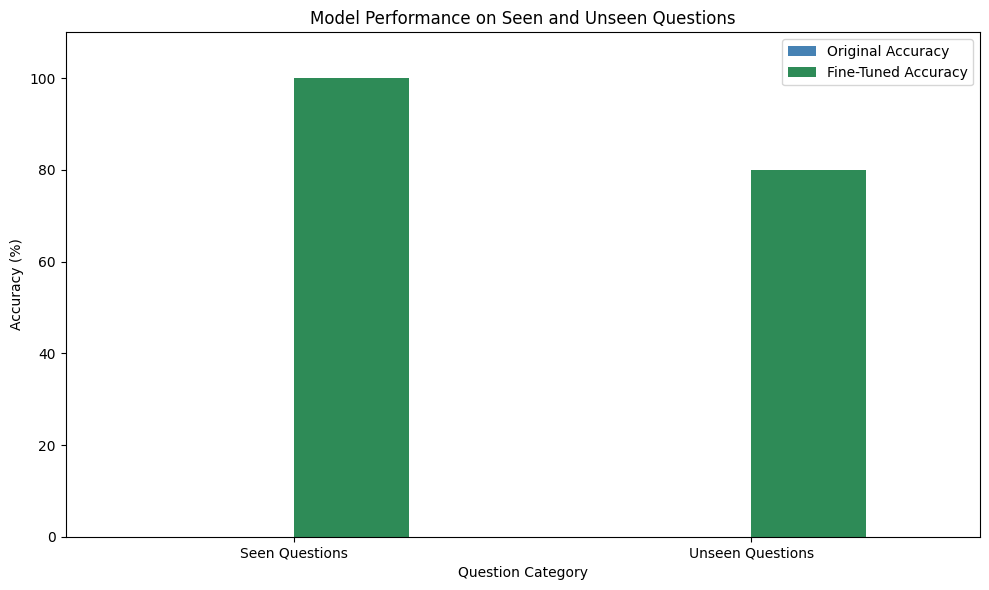

In [55]:
category_df.set_index("Category")[

    [

        "Original Accuracy",

        "Fine-Tuned Accuracy"

    ]

].plot(

    kind="bar",

    figsize=(10, 6),

    color=["steelblue", "seagreen"]

)

plt.title("Model Performance on Seen and Unseen Questions")

plt.ylabel("Accuracy (%)")

plt.xlabel("Question Category")

plt.xticks(rotation=0)

plt.ylim(0, 110)

plt.legend()

plt.tight_layout()

plt.savefig(

    results_dir / "category_comparison.png",

    dpi=300

)

plt.show()

In [56]:
adapter_path = models_dir / "techzone_lora_adapter"

fine_tuned_model.save_pretrained(

    adapter_path

)

tokenizer.save_pretrained(

    adapter_path

)

print("Fine-tuned adapter saved successfully!")

print("Saved location:", adapter_path)

for file in adapter_path.iterdir():

    print(

        file.name,

        round(file.stat().st_size / (1024 ** 2), 3),

        "MB"

    )

Fine-tuned adapter saved successfully!
Saved location: /content/Lab-04-LLM-Fine-Tuning/models/techzone_lora_adapter
merges.txt 1.594 MB
tokenizer_config.json 0.004 MB
adapter_model.safetensors 33.605 MB
vocab.json 2.648 MB
special_tokens_map.json 0.0 MB
tokenizer.json 10.893 MB
README.md 0.005 MB
chat_template.jinja 0.002 MB
added_tokens.json 0.001 MB
adapter_config.json 0.001 MB


In [57]:
model_information = {

    "base_model": MODEL_ID,

    "fine_tuning_method": (

        "QLoRA" if USE_QLORA else "LoRA"

    ),

    "training_examples": len(train_df),

    "validation_examples": len(validation_df),

    "epochs": training_args.num_train_epochs,

    "learning_rate": training_args.learning_rate,

    "lora_rank": lora_config.r,

    "lora_alpha": lora_config.lora_alpha,

    "trainable_parameters": trainable_parameters,

    "total_parameters": total_parameters,

    "trainable_percentage": trainable_percentage,

    "original_accuracy": original_accuracy,

    "fine_tuned_accuracy": fine_tuned_accuracy,

    "validation_loss": validation_loss,

    "perplexity": perplexity

}

with open(

    results_dir / "model_information.json",

    "w"

) as file:

    json.dump(

        model_information,

        file,

        indent=4

    )

print("Model information saved successfully!")

Model information saved successfully!


In [58]:
from peft import PeftModel

# Release the current training model from GPU memory

del trainer
del model
del fine_tuned_model

gc.collect()

torch.cuda.empty_cache()

if USE_QLORA:

    base_model = AutoModelForCausalLM.from_pretrained(

        MODEL_ID,

        quantization_config=bnb_config,

        torch_dtype=COMPUTE_DTYPE,

        device_map={"": 0}

    )

else:

    base_model = AutoModelForCausalLM.from_pretrained(

        MODEL_ID,

        torch_dtype=torch.float32

    ).to("cuda")


tokenizer = AutoTokenizer.from_pretrained(

    adapter_path

)

reloaded_model = PeftModel.from_pretrained(

    base_model,

    adapter_path

)

reloaded_model.eval()

print("Fine-tuned model reloaded successfully!")

Fine-tuned model reloaded successfully!


In [59]:
question = "How much is your laptop cleaning service?"

response = generate_response(

    reloaded_model,

    question

)

print("Question:", question)

print("Answer:", response)

Question: How much is your laptop cleaning service?
Answer: The TechZone laptop cleaning service starts at LKR 2,500.


In [60]:
print("=" * 50)

print("TECHZONE AI CUSTOMER SERVICE ASSISTANT")

print("=" * 50)

print("Type 'exit' to stop the chatbot.\n")

while True:

    question = input("Customer: ")

    if question.lower().strip() == "exit":

        print("Chatbot session ended.")

        break

    if not question.strip():

        continue

    response = generate_response(

        reloaded_model,

        question

    )

    print("\nTechZone AI:", response)

    print()

TECHZONE AI CUSTOMER SERVICE ASSISTANT
Type 'exit' to stop the chatbot.

Customer: Do you provide home delivery?

TechZone AI: Yes. TechZone provides islandwide delivery within Sri Lanka.

Customer: What is the delivery charge?

TechZone AI: The standard TechZone delivery charge is LKR 750.



KeyboardInterrupt: Interrupted by user

## Discussion

This laboratory investigates parameter-efficient
fine-tuning of a pretrained language model using LoRA.

The Qwen2.5-0.5B-Instruct model was selected because
its relatively small parameter count makes it suitable
for limited computational resources.

A custom computer shop question-answer dataset was
created to adapt the model to a specific domain.

LoRA reduces computational requirements by freezing
the pretrained parameters and training additional
low-rank adapter matrices.

The original model and fine-tuned model were evaluated
using identical test questions and generation settings.

Unseen questions were included to investigate whether
the model could generalize beyond exact training
examples.

## Observations

- Original model accuracy: [Actual result]
- Fine-tuned model accuracy: [Actual result]
- Validation loss: [Actual result]
- Validation perplexity: [Actual result]
- Trainable parameter percentage: [Actual result]

Discuss whether the fine-tuned model improved its
knowledge of shop-specific information.

Discuss whether it successfully answered unseen
questions or produced incorrect information.

## Limitations

- Small training dataset.
- Small test dataset.
- Possibility of overfitting.
- Potential hallucinated responses.
- Limited reasoning capabilities.
- Manual evaluation may introduce subjectivity.

## Future Improvements

- Increase the training dataset size.
- Include more diverse customer questions.
- Experiment with different LoRA ranks.
- Compare LoRA with 4-bit QLoRA.
- Investigate different learning rates.
- Include additional unseen test questions.
- Combine fine-tuning with retrieval-augmented generation.

In [61]:
method = "QLoRA" if USE_QLORA else "LoRA"

readme_content = f"""
# Lab 04 – Fine-Tuning an LLM Using LoRA/QLoRA

**Module:** PUSL 3205 – Large Language Models and Generative AI

**Project:** TechZone AI Customer Service Assistant

## 1. Objective

The objective of this laboratory is to fine-tune
a pretrained instruction-tuned language model using
parameter-efficient fine-tuning techniques.

## 2. Tools and Technologies

- Python
- Google Colab
- PyTorch
- Hugging Face Transformers
- Hugging Face Datasets
- PEFT
- TRL
- Accelerate
- Bitsandbytes
- Pandas
- Matplotlib

## 3. Hardware Configuration

| Component | Specification |
|---|---|
| GPU | {gpu_name} |
| GPU Memory | {gpu_memory:.2f} GiB |
| CUDA Version | {torch.version.cuda} |
| Platform | Google Colab |

## 4. Model Selection

- Base Model: {MODEL_ID}
- Model Type: Causal Language Model
- Fine-Tuning Method: {method}
- Domain: Computer Shop Customer Service

## 5. Dataset

A custom question-answer dataset was created for
the fictional TechZone Computer Shop.

| Dataset | Examples |
|---|---:|
| Training | {len(train_df)} |
| Validation | {len(validation_df)} |
| Testing | {len(test_df)} |

The dataset includes questions about products,
pricing, warranty, repairs, delivery and discounts.

## 6. Implementation

1. Installed the required libraries.
2. Identified GPU resources.
3. Loaded the pretrained model and tokenizer.
4. Created a custom question-answer dataset.
5. Tested the original model.
6. Configured PEFT adapters.
7. Fine-tuned the model using SFTTrainer.
8. Evaluated the fine-tuned model.
9. Compared seen and unseen questions.
10. Saved and reloaded the trained adapters.

## 7. Training Configuration

| Hyperparameter | Value |
|---|---|
| Fine-Tuning Method | {method} |
| LoRA Rank | {lora_config.r} |
| LoRA Alpha | {lora_config.lora_alpha} |
| LoRA Dropout | {lora_config.lora_dropout} |
| Learning Rate | {training_args.learning_rate} |
| Epochs | {training_args.num_train_epochs} |
| Batch Size | {training_args.per_device_train_batch_size} |
| Maximum Sequence Length | 256 |
| Optimizer | AdamW |

## 8. Experimental Results

| Metric | Result |
|---|---:|
| Original Model Accuracy | {original_accuracy:.2f}% |
| Fine-Tuned Model Accuracy | {fine_tuned_accuracy:.2f}% |
| Accuracy Difference | {improvement:.2f} percentage points |
| Validation Loss | {validation_loss:.4f} |
| Perplexity | {perplexity:.4f} |
| Total Parameters | {total_parameters:,} |
| Trainable Parameters | {trainable_parameters:,} |
| Trainable Percentage | {trainable_percentage:.4f}% |
| Training Time | {training_time:.2f} seconds |

## 9. Visualizations

### Training Loss

![Training Loss](results/training_loss.png)

### Validation Loss

![Validation Loss](results/validation_loss.png)

### Parameter Distribution

![Parameters](results/parameter_distribution.png)

### Accuracy Comparison

![Accuracy](results/accuracy_comparison.png)

### Seen and Unseen Questions

![Category Comparison](results/category_comparison.png)

## 10. Supporting Evidence

- [Jupyter Notebook](notebooks/lab04_llm_finetuning.ipynb)
- [Training Dataset](data/training_dataset.csv)
- [Validation Dataset](data/validation_dataset.csv)
- [Test Dataset](data/test_dataset.csv)
- [GPU Information](results/gpu_information.json)
- [Training History](results/training_history.csv)
- [Model Comparison](results/model_comparison.csv)
- [Scored Responses](results/scored_model_comparison.csv)
- [Trained Adapter](models/techzone_lora_adapter/)
- [Screenshots](screenshots/)

## 11. Observations and Reflection

The model was fine-tuned using a small domain-specific
dataset. Its responses were compared with the original
model using identical questions.

[Discuss actual changes in answer correctness.]

[Discuss performance on unseen questions.]

[Describe challenges encountered during fine-tuning.]

[Discuss incorrect or hallucinated answers.]

## 12. Learning Outcomes

- Understanding parameter-efficient fine-tuning.
- Configuring LoRA and QLoRA.
- Preparing instruction-based datasets.
- Using Hugging Face SFTTrainer.
- Fine-tuning pretrained language models.
- Evaluating seen and unseen questions.
- Saving and reusing trained adapters.

## 13. Limitations

- Small dataset and test sample.
- Possible overfitting.
- Potential hallucinations.
- Limited generalization.
- Subjective manual evaluation.

## 14. Future Improvements

- Increase dataset size and diversity.
- Compare multiple base models.
- Compare LoRA and QLoRA.
- Experiment with adapter hyperparameters.
- Improve evaluation methodology.

## 15. Conclusion

[Summarize the actual results and learning experience.]

## 16. References

- https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct
- https://huggingface.co/docs/transformers/
- https://huggingface.co/docs/peft/
- https://huggingface.co/docs/trl/
- https://arxiv.org/abs/2106.09685
- https://arxiv.org/abs/2305.14314
"""

with open(

    project_dir / "README.md",

    "w",

    encoding="utf-8"

) as file:

    file.write(readme_content.strip())

print("README.md created successfully!")

README.md created successfully!


In [62]:
with open(

    project_dir / "requirements.txt",

    "w"

) as file:

    for package in packages:

        version = metadata.version(package)

        file.write(

            f"{package}=={version}\n"

        )

    for package in ["pandas", "numpy", "matplotlib"]:

        file.write(

            f"{package}=="

            f"{metadata.version(package)}\n"

        )

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [63]:
import shutil

from google.colab import files

archive_path = shutil.make_archive(

    "/content/Lab-04-LLM-Fine-Tuning",

    "zip",

    root_dir="/content",

    base_dir="Lab-04-LLM-Fine-Tuning"

)

print("ZIP file created:", archive_path)

files.download(archive_path)

ZIP file created: /content/Lab-04-LLM-Fine-Tuning.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>